# Progress Report 1: Data Exploration

**CS 4330 – Data Science**

**Dr. Dogdu**
  
Eryna Plong  
Bunlong Tan  
Tanner Love  

### Setup

**Libraries and data folder:** the first cell imports the libraries and finds the data folder. On Colab it uses the shared Google Drive folder, and when run locally it uses ../dataset.

In [1]:
#==============================================================
#=========== DO NOT MODIFY THIS CODE CELL =====================
#==============================================================

import glob, pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

try:
    # Colab: read the data from the shared Google Drive folder
    from google.colab import drive
    drive.mount('/content/drive')
    DATA = (glob.glob('/content/drive/*/vulngraph-gnn/dataset') + glob.glob('/content/drive/*/*/vulngraph-gnn/dataset'))[0]
except ImportError:
    # Local: the dataset folder sits next to this notebook's folder in the repo
    DATA = '../dataset'

U = f'{DATA}/uckg' # U for UCKG
print('Using', DATA)

Using ../dataset


**Loading the data:** the next cell reads the NVD table (one row per CVE) and the knowledge graph's node and edge tables from the uckg folder.

In [2]:
#==============================================================
#=========== DO NOT MODIFY THIS CODE CELL =====================
#==============================================================

# --- Main table: one row per CVE (label = severity or base_score) # parse_dates=['published', 'last_modified'] converts to real dates ---
nvd = pd.read_csv(f'{DATA}/nvd_cves.csv', parse_dates=['published', 'last_modified'], low_memory=False)

# --- Graph nodes ---
cwes   = pd.read_csv(f'{U}/cwes.csv')
capecs = pd.read_csv(f'{U}/capecs.csv')
attack = pd.read_csv(f'{U}/attack_techniques.csv')

# --- Graph edges ---
cve_cwe      = pd.read_csv(f'{U}/edges_cve_cwe.csv')
cve_cpe      = pd.read_csv(f'{U}/edges_cve_cpe.csv')
capec_cwe    = pd.read_csv(f'{U}/edges_capec_cwe.csv')
capec_attack = pd.read_csv(f'{U}/edges_capec_attack.csv')

**Building df:** the next cell combines the NVD table with four counts from the knowledge graph into one table, df. The steps are explained after the cell.

In [3]:
# --- Combined CVE-level table: NVD + graph counts ---
cve_capec  = cve_cwe.merge(capec_cwe, on='cwe_id')[['cve_id', 'capec_id']].drop_duplicates()
cve_attack = cve_capec.merge(capec_attack, on='capec_id')[['cve_id', 'attack_id']].drop_duplicates()

graph_feats = pd.DataFrame({
    'n_cwe':    cve_cwe.groupby('cve_id').size(),
    'n_cpe':    cve_cpe.groupby('cve_id').size(),
    'n_capec':  cve_capec.groupby('cve_id').size(),
    'n_attack': cve_attack.groupby('cve_id').size(),
})

df = nvd.merge(graph_feats, left_on='cve_id', right_index=True, how='left')
df[graph_feats.columns] = df[graph_feats.columns].fillna(0).astype(int)

# Keep only CVEs that have a v3 label
df = df[df['severity'].notna() & (df['severity'] != 'NONE')]

"df" is the main table for modeling. It has one row per CVE: all the NVD columns plus four counts taken from the knowledge graph.

Step by step:

1. cve_capec links each CVE to attack patterns (CAPEC). CVEs don't connect to CAPEC directly, so it goes through the CWE: CVE → CWE → CAPEC. drop_duplicates() makes sure a CVE that reaches the same CAPEC through two CWEs counts it once.

2. cve_attack goes one step further, CVE → CWE → CAPEC → ATT&CK technique, to link each CVE to the ATT&CK techniques it could be used for.

3. graph_feats counts each CVE's links:

- n_cwe: how many weakness types it's tagged with
- n_cpe: how many affected product versions it lists
- n_capec: how many attack patterns it reaches
- n_attack: how many ATT&CK techniques it reaches


4. The merge attaches those four counts to the NVD table on cve_id. how='left' - keeps every NVD CVE, even ones with no graph links. Those get NaN, which fillna(0) turns into 0.

5. The filter drops CVEs with no v3 severity (mostly older ones scored only under v2) and the 13 marked NONE, so every row has a label to train on.

About 307k rows, with:

- the label (severity, or base_score for regression)
- features you can use: description, dates, vendors and products, CWE, and the four graph counts

In [4]:
# df is the main data frame and can be seen below
print(f'\n=== df  {df.shape} ===')
display(df.head())


=== df  (307239, 32) ===


,cve_id,published,last_modified,vuln_status,description,cvss3_version,cvss3_source,base_score,severity,vector_string,...,cvss4_base_score,cvss4_severity,cwe,all_cwes,vendors,products,n_cwe,n_cpe,n_capec,n_attack
6,CVE-1999-0084,1990-05-01 04:00:00,2026-06-16 21:47:32.553,Modified,Certain NFS servers allow users to use mknod t...,3.1,Secondary,8.4,HIGH,CVSS:3.1/AV:L/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-269,CWE-269,sun,sun:nfs,1,1,3,1
92,CVE-1999-0066,1995-07-31 04:00:00,2026-06-16 21:47:29.853,Modified,AnyForm CGI remote execution.,3.1,Secondary,9.8,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,NaN,NaN,john_s._roberts,john_s._roberts:anyform,0,1,0,0
130,CVE-1999-0022,1996-07-03 04:00:00,2026-06-16 21:47:22.167,Modified,Local user gains root privileges via buffer ov...,3.1,Secondary,7.8,HIGH,CVSS:3.1/AV:L/AC:L/PR:L/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-125,CWE-125,bsdi;freebsd;hp;ibm;sgi;sun,bsdi:bsd_os;freebsd:freebsd;hp:hp-ux;ibm:aix;s...,1,2,1,0
171,CVE-1999-0043,1996-12-04 05:00:00,2026-06-16 21:47:26.437,Modified,Command execution via shell metachars in INN d...,3.1,Secondary,9.8,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-78,CWE-78,bsdi;caldera;isc;nec;netscape;redhat,bsdi:bsd_os;caldera:openlinux;isc:inn;nec:goah...,1,3,5,0
197,CVE-1999-0236,1997-01-01 05:00:00,2026-06-16 21:47:58.393,Modified,ScriptAlias directory in NCSA and Apache httpd...,3.1,Primary,7.5,HIGH,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:N/A:N,...,NaN,NaN,NaN,NaN,apache;illinois,apache:http_server;illinois:ncsa_httpd,0,1,0,0


### Task 1

**Dataset structure:** df.info() lists every column, its data type, and how many values are filled in.

In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 307239 entries, 6 to 408815
Data columns (total 32 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   cve_id                  307239 non-null  str           
 1   published               307239 non-null  datetime64[us]
 2   last_modified           307239 non-null  datetime64[us]
 3   vuln_status             307239 non-null  str           
 4   description             307239 non-null  str           
 5   cvss3_version           307239 non-null  float64       
 6   cvss3_source            307239 non-null  str           
 7   base_score              307239 non-null  float64       
 8   severity                307239 non-null  str           
 9   vector_string           307239 non-null  str           
 10  attack_vector           307239 non-null  str           
 11  attack_complexity       307239 non-null  str           
 12  privileges_required     307239 non-null  str  

df has 307,239 rows and 32 columns: 20 text columns, 10 number columns, and 2 dates. Most columns are fully filled in. The gaps are in cvss2 (about 40% filled), cvss4 (about 11%), cwe (91%), and vendors and products (81%).

**Numerical features:** the minimum and maximum of every number column.

In [6]:
# Identify numerical features and display their minimum and maximum values.
numerical_cols = df.select_dtypes(include=["int64", "float64"])
display(numerical_cols.agg(["min", "max"]))

,cvss3_version,base_score,exploitability_score,impact_score,cvss2_base_score,cvss4_base_score,n_cwe,n_cpe,n_capec,n_attack
min,3.0,1.6,0.1,1.4,0.0,0.0,0,0,0,0
max,3.1,10.0,3.9,6.0,10.0,10.0,9,2723,134,64


The CVSS scores stay inside their fixed ranges: base score 1.6 to 10, exploitability 0.1 to 3.9, and impact 1.4 to 6.0. The graph counts have long tails. Most CVEs have only a few links, but n_cpe reaches 2,723 and n_capec reaches 134. cvss3_version is stored as a number, but it is really a category (3.0 or 3.1).

**Categorical features:** the possible values of each column that has a small, fixed set of categories.

In [7]:
# Identify categorical features and display their possible values.
categorical_cols = [
    "severity",
    "vuln_status",
    "cvss3_source",
    "attack_vector",
    "attack_complexity",
    "privileges_required",
    "user_interaction",
    "scope",
    "confidentiality_impact",
    "integrity_impact",
    "availability_impact",
    "cvss3_version",
    "cvss2_severity",
    "cvss4_severity"
]

for col in categorical_cols:
    print(col, ":", df[col].dropna().unique().tolist(), "\n")

severity : ['HIGH', 'CRITICAL', 'MEDIUM', 'LOW'] 

vuln_status : ['Modified', 'Analyzed', 'Deferred', 'Awaiting Analysis', 'Received', 'Undergoing Analysis'] 

cvss3_source : ['Secondary', 'Primary'] 

attack_vector : ['LOCAL', 'NETWORK', 'ADJACENT_NETWORK', 'PHYSICAL'] 

attack_complexity : ['LOW', 'HIGH'] 



privileges_required : ['NONE', 'LOW', 'HIGH'] 

user_interaction : ['NONE', 'REQUIRED'] 

scope : ['UNCHANGED', 'CHANGED'] 

confidentiality_impact : ['HIGH', 'LOW', 'NONE'] 

integrity_impact : ['HIGH', 'NONE', 'LOW'] 

availability_impact : ['HIGH', 'NONE', 'LOW'] 

cvss3_version : [3.1, 3.0] 

cvss2_severity : ['HIGH', 'MEDIUM', 'LOW'] 

cvss4_severity : ['MEDIUM', 'HIGH', 'CRITICAL', 'LOW', 'NONE'] 



Every categorical feature has only 2 to 6 values. severity, the label, has 4 levels: LOW, MEDIUM, HIGH, and CRITICAL. cvss3_source shows who gave the score: NVD itself (Primary) or the organization that reported the CVE (Secondary). The CVSS metric columns (attack_vector, scope, and the three impact columns) are the parts the base score is calculated from, so they should not be used as features.

**Other features:** IDs, free text, and columns with too many distinct values to list. The code counts their unique values instead.

In [8]:
# Summarize other features that contain identifiers, text,
# or a large number of distinct categorical values.
other_cols = [
    "cve_id",
    "description",
    "vector_string",
    "cwe",
    "all_cwes",
    "vendors",
    "products"
]

for col in other_cols:
    print(col, ":", df[col].nunique(), "unique values")

cve_id : 307239 unique values


description : 290690 unique values
vector_string : 2210 unique values
cwe : 764 unique values
all_cwes : 6079 unique values
vendors : 27152 unique values
products : 57499 unique values


cve_id is unique for every row, so it is an ID and not a feature. About 16,500 descriptions are repeats, which means some CVEs share the exact same text. There are 764 different main CWEs, 27,152 vendors, and 57,499 products, which is far too many to treat as simple categories.

**Date features:** the earliest and latest date in each date column.

In [9]:
# Display the earliest and latest dates for the date features.
display(df[["published", "last_modified"]].agg(["min", "max"]))

,published,last_modified
min,1990-05-01 04:00:00.000,2026-06-16 21:47:19.097
max,2026-10-16 06:17:13.630,2026-10-16 06:17:13.630


CVEs in df were published between May 1990 and October 2026. Every last_modified date falls between June and October 2026, which suggests NVD recently updated all of its records at once. That makes last_modified not useful as a feature.

### Task 2


Each cell below makes one of the five single feature plots, using all CVEs in df.

**Histogram:** how many CVEs fall at each base score, grouped into 20 bins.

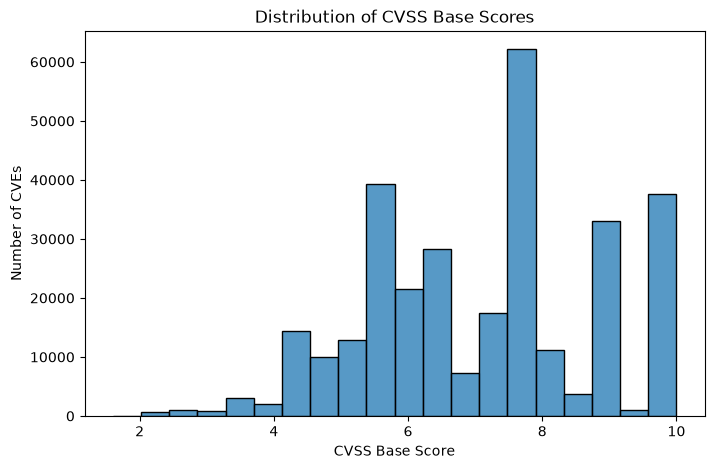

In [10]:
# 1. Histogram - Distribution of CVSS base scores
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="base_score", bins=20)
plt.title("Distribution of CVSS Base Scores")
plt.xlabel("CVSS Base Score")
plt.ylabel("Number of CVEs")
plt.show()

The histogram shows that most CVEs have base scores between 5 and 10, with the highest frequency around 7.5. This suggests that the dataset contains more medium- to high-severity vulnerabilities than low-severity ones.

**KDE plot:** a smooth curve showing how the exploitability scores are spread out.

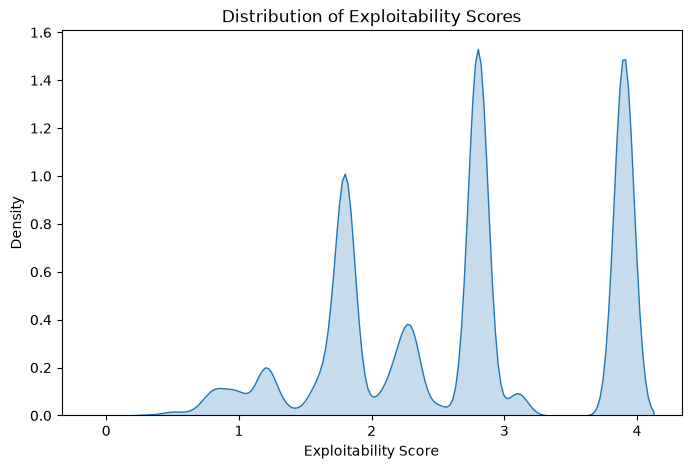

In [11]:
# 2. KDE Plot - Distribution of exploitability scores
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x="exploitability_score", fill=True)
plt.title("Distribution of Exploitability Scores")
plt.xlabel("Exploitability Score")
plt.ylabel("Density")
plt.show()

The KDE plot shows several distinct peaks, particularly around 1.8, 2.8, and 3.9. This indicates that exploitability scores are concentrated around specific values rather than being evenly distributed.

**Count plot:** how many CVEs are in each severity level, from LOW to CRITICAL.

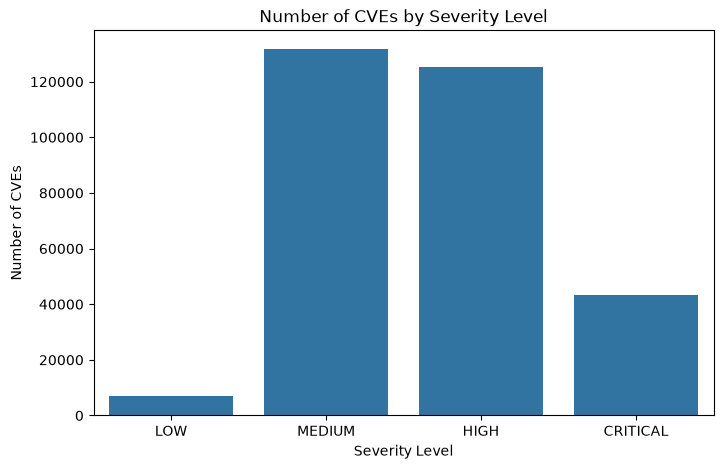

In [12]:
# 3. Count Plot - Number of CVEs by severity level
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="severity",
    order=["LOW", "MEDIUM", "HIGH", "CRITICAL"]
)
plt.title("Number of CVEs by Severity Level")
plt.xlabel("Severity Level")
plt.ylabel("Number of CVEs")
plt.show()

The count plot shows that MEDIUM is the most common severity level, followed closely by HIGH. CRITICAL vulnerabilities are less frequent, while LOW vulnerabilities are the least common. This indicates that most vulnerabilities in the dataset are classified as medium or high severity.

**Box plot:** the number of CWE links per CVE (n_cwe), showing the middle range and the outliers.

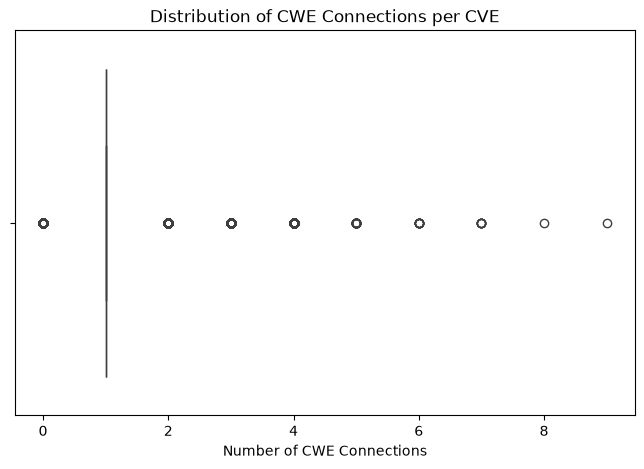

In [13]:
# 4. Box Plot - Distribution of CWE connections per CVE
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="n_cwe")
plt.title("Distribution of CWE Connections per CVE")
plt.xlabel("Number of CWE Connections")
plt.show()

The box plot shows that most CVEs have approximately one CWE connection, with very little variation among the majority of observations. Some CVEs have multiple CWE connections, reaching up to nine, which appear as outliers. CVEs with no CWE connection (0) also appear as outliers.

**Violin plot:** the spread of impact scores, with wider parts where more CVEs cluster.

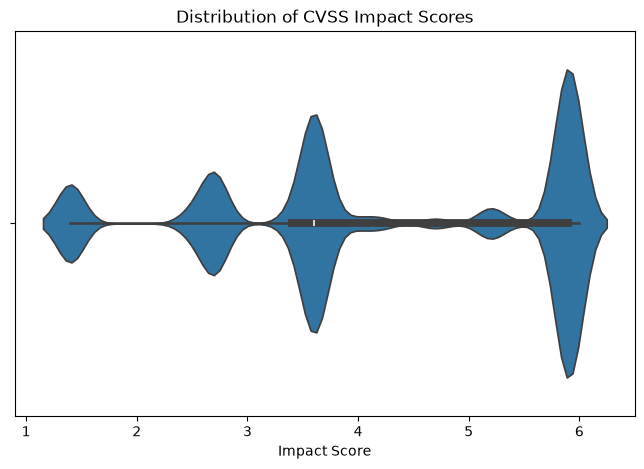

In [14]:
# 5. Violin Plot - Distribution of CVSS impact scores
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="impact_score")
plt.title("Distribution of CVSS Impact Scores")
plt.xlabel("Impact Score")
plt.show()

The violin plot shows that impact scores are concentrated around 3.6 and 5.9, with smaller concentrations around 1.4 and 2.7. This suggests that vulnerabilities tend to cluster around particular impact levels rather than being evenly distributed across the score range.

### Task 3

The first cell takes a random sample of 1,000 CVEs (sample_df) and adds a pub_year column. The scatter and swarm plots use the sample because 307k points would be unreadable and too slow for a swarm plot.

In [15]:
# Show an example of each of the following two feature plots on the dataset
# Use hue, style, and size parameters as well. Explain the results of each plot briefly

sample_df = df.sample(1000, random_state=42).assign(pub_year=lambda d: d['published'].dt.year)  # Random sample so the scatter and swarm plots stay readable

**Scatter plot:** base score against publication year, using the sample. Hue and style show severity, and size shows the number of affected products (n_cpe).

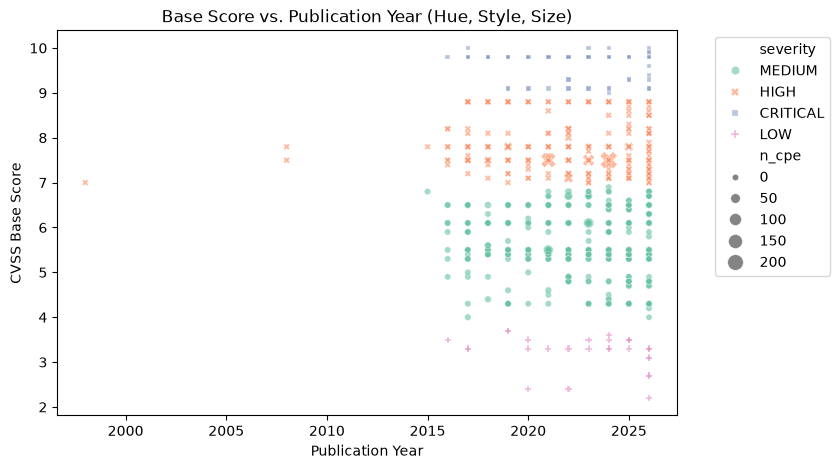

In [16]:
# Base score over time
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_df,
    x='pub_year',     # Year the CVE was published
    y='base_score',   # CVSS v3 base score
    hue='severity',   # Colouring
    style='severity', # Maps marker shapes to severity tiers
    size='n_cpe',     # Scales marker sizes by affected product counts
    sizes=(20, 150),  # Controls the minimum and maximum marker sizes
    alpha=0.6,        # Transparency to see markers overlapping
    palette='Set2'
)
plt.title('Base Score vs. Publication Year (Hue, Style, Size)')
plt.xlabel('Publication Year')
plt.ylabel('CVSS Base Score')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Clean legend placement
plt.show()

Each severity level sits in its own band of base scores, since severity is set by the score. Most CVEs in the sample were published after 2016. Marker size shows the number of affected products (n_cpe), and most markers are small at every score, so product count does not seem to grow with severity.

**Strip plot:** number of ATT&CK links (n_attack) for each severity level, using all CVEs. Hue shows severity and jitter spreads the points out.

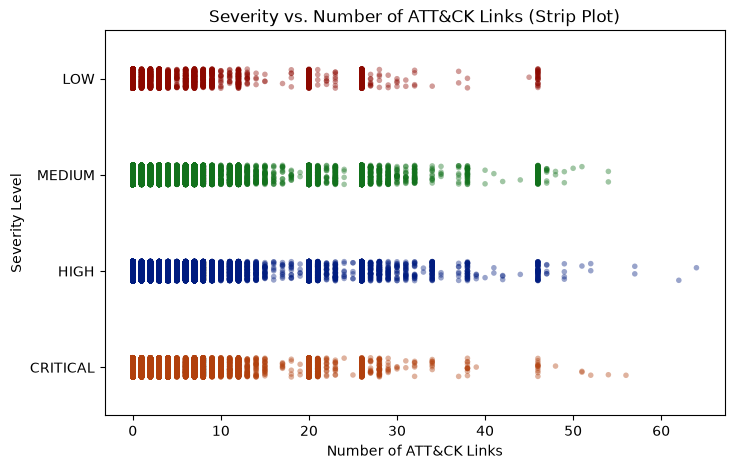

In [17]:
# Categorical-numerical comparison plot
plt.figure(figsize=(8, 5))
sns.stripplot(
    data=df,
    x='n_attack',                                 # Number of ATT&CK techniques (numerical)
    y='severity',                                 # Severity level (categorical)
    order=['LOW', 'MEDIUM', 'HIGH', 'CRITICAL'],  # Its order of severity
    hue='severity',                               # Colouring
    legend=False,
    size=4,                                       # Controls marker size
    jitter=True,                                  # Density Distribution and Concentration of Data points within each severity tier
    alpha=0.4,                                    # Transparency
    palette='dark'
)
plt.title('Severity vs. Number of ATT&CK Links (Strip Plot)')
plt.xlabel('Number of ATT&CK Links')
plt.ylabel('Severity Level')
plt.show()

Every severity level has CVEs with anywhere from 0 to about 50 ATT&CK links, and the points are spread in a similar way. The number of links does not clearly increase with severity.

**Swarm plot:** publication date for each severity level, using the sample. Hue shows severity, and a small marker size lets every point fit without overlapping.

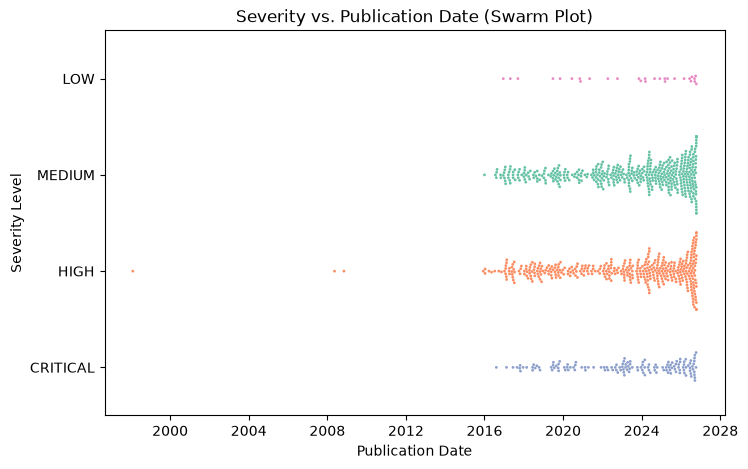

In [18]:
# Categorical distribution (NOTICE: This will be a cluster yet giving clear visual due to the nature of swarmplot)
plt.figure(figsize=(8, 5))
sns.swarmplot(
    data=sample_df,
    x='published',                                # Date the CVE was published (numerical)
    y='severity',                                 # Severity level (categorical)
    order=['LOW', 'MEDIUM', 'HIGH', 'CRITICAL'],  # Its order of severity
    hue='severity',                               # Colouring
    legend=False,
    size=2,                                       # Controls marker size for clean spacing
    palette='Set2'
)
plt.title('Severity vs. Publication Date (Swarm Plot)')
plt.xlabel('Publication Date')
plt.ylabel('Severity Level')
plt.show()

Most CVEs were published after 2016, and MEDIUM and HIGH get much denser toward 2025 and 2026 as more CVEs are published each year. LOW is rare in every year.

### Task 4

Task 4 summarizes df with the three methods from the assignment, then works through the exploratory data analysis steps.

**df.shape:** the number of rows and columns.

In [19]:
# Dataset dimensions
print(f"Dataset Dimensions (Rows, Columns): {df.shape}")

Dataset Dimensions (Rows, Columns): (307239, 32)


df has 307,239 rows (one per CVE) and 32 columns (features).

**df.info():** each column's name, data type, and number of non-missing values. This checks that the scores and graph counts are stored as numbers rather than text.

In [20]:
df.info()

<class 'pandas.DataFrame'>
Index: 307239 entries, 6 to 408815
Data columns (total 32 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   cve_id                  307239 non-null  str           
 1   published               307239 non-null  datetime64[us]
 2   last_modified           307239 non-null  datetime64[us]
 3   vuln_status             307239 non-null  str           
 4   description             307239 non-null  str           
 5   cvss3_version           307239 non-null  float64       
 6   cvss3_source            307239 non-null  str           
 7   base_score              307239 non-null  float64       
 8   severity                307239 non-null  str           
 9   vector_string           307239 non-null  str           
 10  attack_vector           307239 non-null  str           
 11  attack_complexity       307239 non-null  str           
 12  privileges_required     307239 non-null  str  

All the CVSS scores and graph counts are stored as numbers (float64 or int64), and published and last_modified are real dates. Everything else is text. So there are no type mismatches to fix before modeling.

**df.describe(include="all"):** summary statistics for every column. Number columns get the mean, standard deviation, minimum, maximum, and quartiles. Text columns get the number of unique values, the most common value (top), and how often it appears (freq).

In [21]:
display(df.describe(include="all"))

,cve_id,published,last_modified,vuln_status,description,cvss3_version,cvss3_source,base_score,severity,vector_string,...,cvss4_base_score,cvss4_severity,cwe,all_cwes,vendors,products,n_cwe,n_cpe,n_capec,n_attack
count,307239,307239,307239,307239,307239,307239.000000,307239,307239.000000,307239,307239,...,34787.000000,34787,280868,280868,248248,248248,307239.000000,307239.000000,307239.000000,307239.000000
unique,307239,NaN,NaN,6,290690,NaN,2,NaN,4,2210,...,NaN,5,764,6079,27152,57499,NaN,NaN,NaN,NaN
top,CVE-1999-0084,NaN,NaN,Modified,Adobe Experience Manager versions 6.5.22 and e...,NaN,Primary,NaN,MEDIUM,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,MEDIUM,CWE-79,CWE-79,google,linux:linux_kernel,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,171789,222,NaN,194996,NaN,131799,28188,...,NaN,14842,40523,38694,12859,11624,NaN,NaN,NaN,NaN
mean,NaN,2023-04-10 22:14:25.562760,2026-07-04 07:37:54.238602,NaN,NaN,3.085923,NaN,7.071672,NaN,NaN,...,6.135625,NaN,NaN,NaN,NaN,NaN,1.005790,2.196170,7.829410,2.370324
min,NaN,1990-05-01 04:00:00,2026-06-16 21:47:19.097000,NaN,NaN,3.000000,NaN,1.600000,NaN,NaN,...,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000
25%,NaN,2021-02-17 14:15:15.053500,2026-06-17 03:21:16.101500,NaN,NaN,3.100000,NaN,5.500000,NaN,NaN,...,5.100000,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,0.000000,0.000000
50%,NaN,2024-02-29 01:44:16.287000,2026-06-17 06:47:40.333000,NaN,NaN,3.100000,NaN,7.200000,NaN,NaN,...,6.700000,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,3.000000,0.000000
75%,NaN,2025-12-10 21:16:04.016500,2026-06-17 10:36:48.096500,NaN,NaN,3.100000,NaN,8.200000,NaN,NaN,...,8.400000,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,6.000000,1.000000
max,NaN,2026-10-16 06:17:13.630000,2026-10-16 06:17:13.630000,NaN,NaN,3.100000,NaN,10.000000,NaN,NaN,...,10.000000,NaN,NaN,NaN,NaN,NaN,9.000000,2723.000000,134.000000,64.000000


The average base score is 7.07 and the median is 7.2, so the typical CVE is rated HIGH, even though MEDIUM is the most common single level (131,799 CVEs). Most CVEs can be attacked over the network (226,469, or 74%). The most common weakness is CWE-79, cross-site scripting (40,523 CVEs). Google is the most common vendor and the Linux kernel is the most common product. n_cpe has a mean of 2.2 but a standard deviation of 15.9, which shows that a few CVEs list a huge number of products.

#### Exploratory data analysis steps

Step 1 (understand the data) is covered by df.shape and df.info() above and by Task 1. The cells below cover steps 2 to 4.

**Step 2, relationships between features:** a heatmap of the correlation between every pair of numerical features. Values near 1 or -1 are strong and values near 0 are weak. The sign gives the direction. cvss3_version is left out because it is really a category.

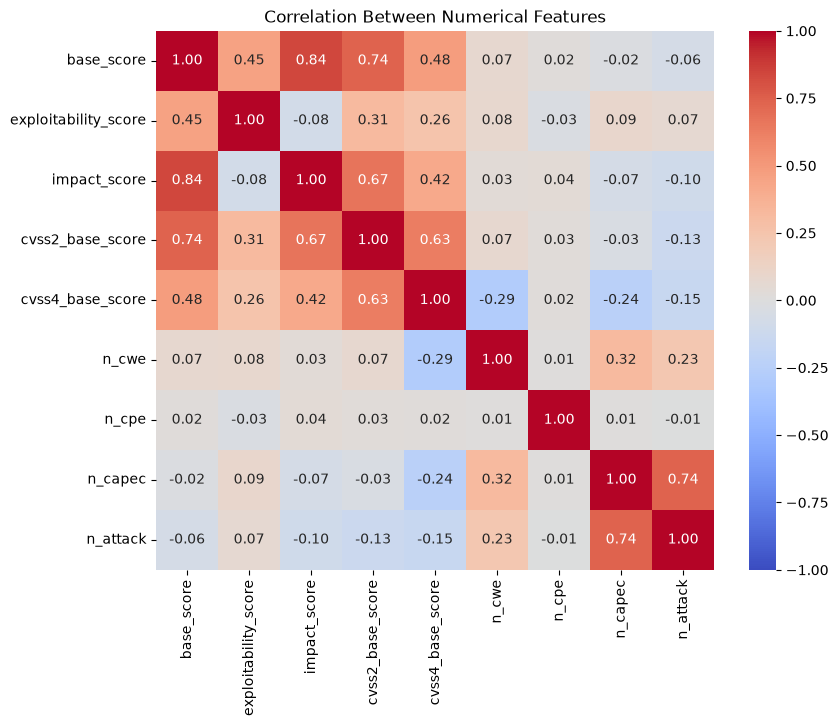

In [22]:
# Numerical features used in the EDA steps (cvss3_version left out because it is a category)
numeric_features = ["base_score", "exploitability_score", "impact_score", "cvss2_base_score",
                    "cvss4_base_score", "n_cwe", "n_cpe", "n_capec", "n_attack"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Numerical Features")
plt.show()

base_score has a strong positive correlation with impact_score (0.84) and cvss2_base_score (0.74), and a moderate positive correlation with exploitability_score (0.45) and cvss4_base_score (0.48). This makes sense because these are all parts or versions of the same score. n_capec and n_attack are strongly correlated (0.74), because ATT&CK techniques are reached through CAPEC. The graph counts have almost no correlation with base_score (between -0.06 and 0.07), so on their own they have only a very weak linear relationship with severity.

**Step 3, shape of the data:** the skewness of each numerical feature. A value near 0 means the distribution is symmetric, above 0 means it has a long tail to the right, and below 0 means a long tail to the left.

In [23]:
display(df[numeric_features].skew().round(2).to_frame("skewness"))

,skewness
base_score,-0.09
exploitability_score,-0.08
impact_score,-0.28
cvss2_base_score,0.26
cvss4_base_score,-0.53
n_cwe,0.61
n_cpe,35.28
n_capec,2.77
n_attack,3.29


base_score (-0.09) and exploitability_score (-0.08) are close to symmetric. impact_score (-0.28) is slightly skewed left, cvss2_base_score (0.26) slightly right, and cvss4_base_score (-0.53) moderately left. All four graph counts are skewed right: n_cwe (0.61) moderately, and n_capec (2.77), n_attack (3.29), and especially n_cpe (35.28) very strongly. This is because most CVEs have only a few links while a few have very many.

**Step 4, missing data:** the number of missing values in each column.

In [24]:
display(df.isnull().sum())

cve_id                         0
published                      0
last_modified                  0
vuln_status                    0
description                    0
cvss3_version                  0
cvss3_source                   0
base_score                     0
severity                       0
vector_string                  0
attack_vector                  0
attack_complexity              0
privileges_required            0
user_interaction               0
scope                          0
confidentiality_impact         0
integrity_impact               0
availability_impact            0
exploitability_score           0
impact_score                   0
cvss2_base_score          182995
cvss2_severity            182995
cvss4_base_score          272452
cvss4_severity            272452
cwe                        26371
all_cwes                   26371
vendors                    58991
products                   58991
n_cwe                          0
n_cpe                          0
n_capec   

Only eight columns have missing values. cvss4 is missing for 272,452 CVEs (89%) and cvss2 for 182,995 (60%), because NVD stopped giving v2 scores to newer CVEs and v4 is still new. cwe is missing for 26,371 CVEs, and vendors and products for 58,991. The label columns (severity and base_score) have no missing values.

**Step 4, outliers:** how many values in each numerical feature fall more than 1.5 times the interquartile range (IQR) below the first quartile or above the third quartile. This is the same rule the box plot in Task 2 uses.

In [25]:
# Count values outside 1.5 x IQR, the same rule the box plot uses
q1 = df[numeric_features].quantile(0.25)
q3 = df[numeric_features].quantile(0.75)
iqr = q3 - q1
outliers = (df[numeric_features] < q1 - 1.5 * iqr) | (df[numeric_features] > q3 + 1.5 * iqr)
display(outliers.sum().to_frame("outliers"))

,outliers
base_score,0
exploitability_score,0
impact_score,0
cvss2_base_score,0
cvss4_base_score,40
n_cwe,66265
n_cpe,93116
n_capec,37744
n_attack,69381


The main CVSS scores have no outliers because they stay on a fixed 0 to 10 scale. cvss4_base_score has 40, which are its lowest scores. The graph counts have many: 93,116 for n_cpe, 69,381 for n_attack, 66,265 for n_cwe, and 37,744 for n_capec. For n_cwe, almost every CVE has exactly 1, so every 0 and every value of 2 or more counts as an outlier. These are natural outliers rather than errors, and Task 6 looks at how to handle them.

### Task 5

Task 5 uses the plots built into pandas to look at every numerical feature at once: `df.hist()`, `df.boxplot()`, and `pd.plotting.scatter_matrix`. We also add `sns.pairplot`, which is the seaborn version of a scatter matrix.

**Histograms:** `df.hist()` draws one histogram for each numerical feature, so we can compare their shapes side by side.

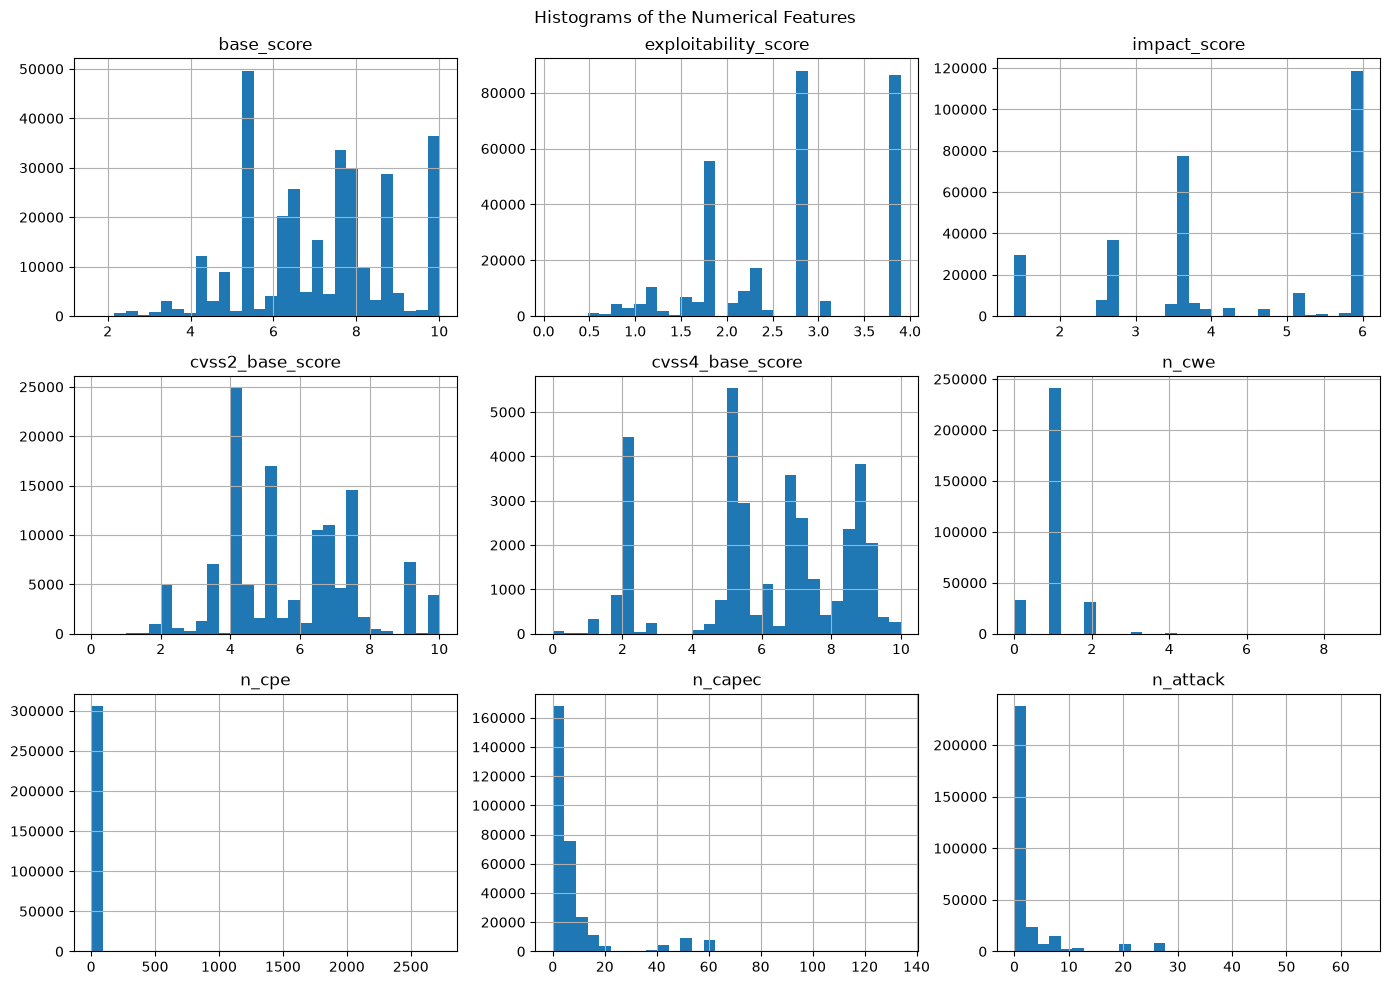

In [26]:
df[numeric_features].hist(bins=30, figsize=(14, 10), layout=(3, 3))
plt.suptitle("Histograms of the Numerical Features")
plt.tight_layout()
plt.show()

The CVSS scores are spiky with gaps between the bars, because they come from a fixed table of metric values, so only certain numbers are possible. base_score sits mostly between 5.5 and 8.2, while cvss2_base_score sits lower, mostly between 4.3 and 7.2. exploitability_score tops out at 3.9 and impact_score at 6.0. The graph counts are squashed against 0 because a few very large values stretch the x-axis. n_cpe is the worst case: almost every CVE is in the first bar, but the axis runs all the way to 2,723.

**Box plot of the scores:** `df.boxplot()` on the five CVSS score columns. They all use the same 0 to 10 scale, so they can share one axis. The graph counts are left out here because their long tails would squash the scores.

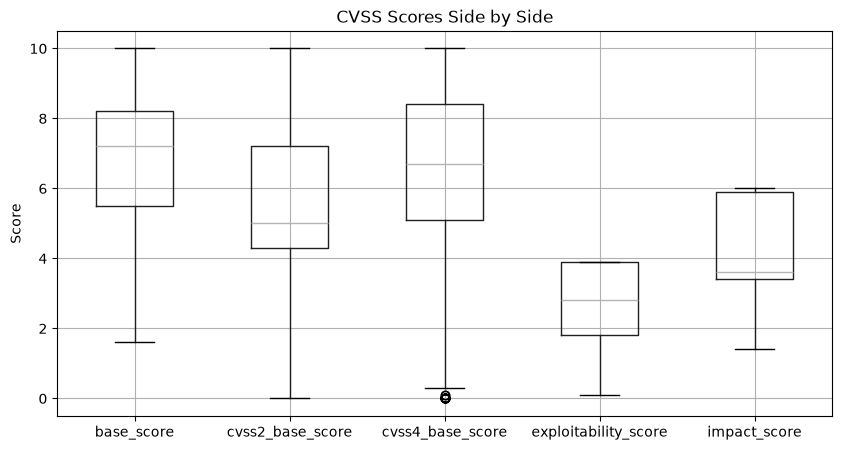

In [27]:
score_cols = ["base_score", "cvss2_base_score", "cvss4_base_score", "exploitability_score", "impact_score"]

plt.figure(figsize=(10, 5))
df.boxplot(column=score_cols)
plt.title("CVSS Scores Side by Side")
plt.ylabel("Score")
plt.show()

The line in each box is the median. base_score (v3) has a median of 7.2, cvss2_base_score of 5.0, and cvss4_base_score of 6.7, so the same kind of CVE scores about two points lower under v2. The v4 box has a few outliers at the bottom, mostly the 38 CVEs that v4 scores as 0. exploitability_score (up to 3.9) and impact_score (up to 6.0) have smaller ranges because they are the two parts that make up the base score, not full scores.

**Box plot by severity:** `df.boxplot(by=...)` draws one box per severity level for each graph count, to see if more severe CVEs have more CWE, CAPEC, or ATT&CK links.

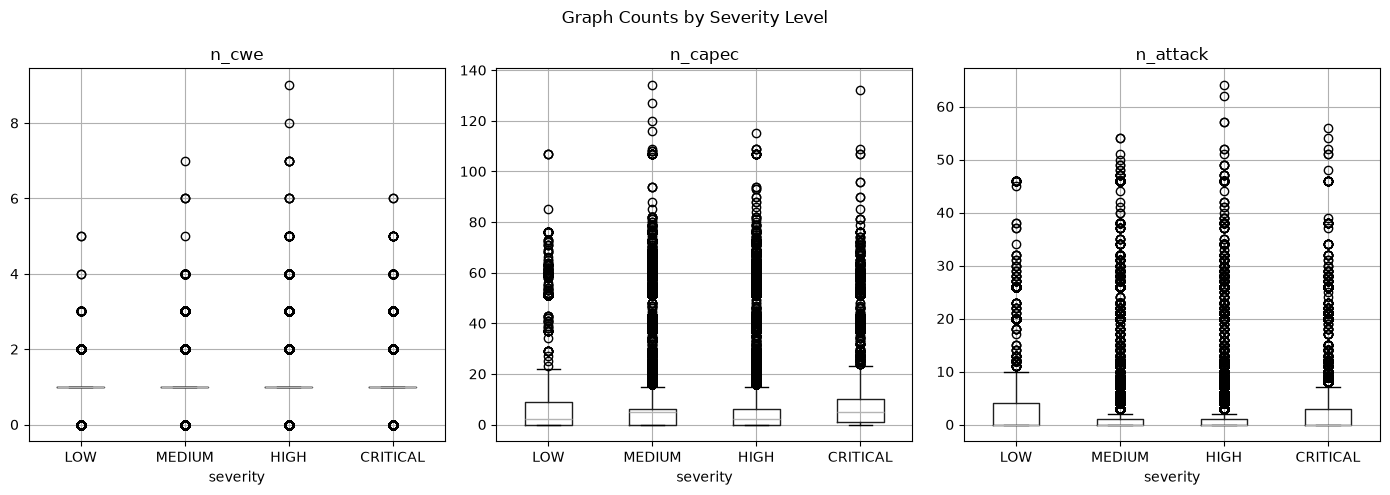

In [28]:
severity_order = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]

# Ordered category so the boxes run from LOW to CRITICAL instead of alphabetically
df_by_severity = df.assign(severity=pd.Categorical(df["severity"], categories=severity_order, ordered=True))
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for col, ax in zip(["n_cwe", "n_capec", "n_attack"], axes):
    df_by_severity.boxplot(column=col, by="severity", ax=ax)  # One plot per count, so each gets its own y-axis
plt.suptitle("Graph Counts by Severity Level")
plt.tight_layout()
plt.show()

The boxes look about the same at every severity level. The median is 1 CWE for all four levels, and the median CAPEC count is 2 to 5 with no steady rise from LOW to CRITICAL. LOW CVEs actually have the highest average CAPEC (10.5) and ATT&CK (4.4) counts. Every level has a long tail of outliers. So the number of graph links does not tell us much about severity on its own.

**Scatter matrix:** `pd.plotting.scatter_matrix` plots every pair of features against each other, with a histogram of each feature on the diagonal. Plotting 307,239 points per panel is slow and unreadable, so we use a random sample of 2,000 CVEs. `random_state=42` makes the sample the same every time the notebook runs.

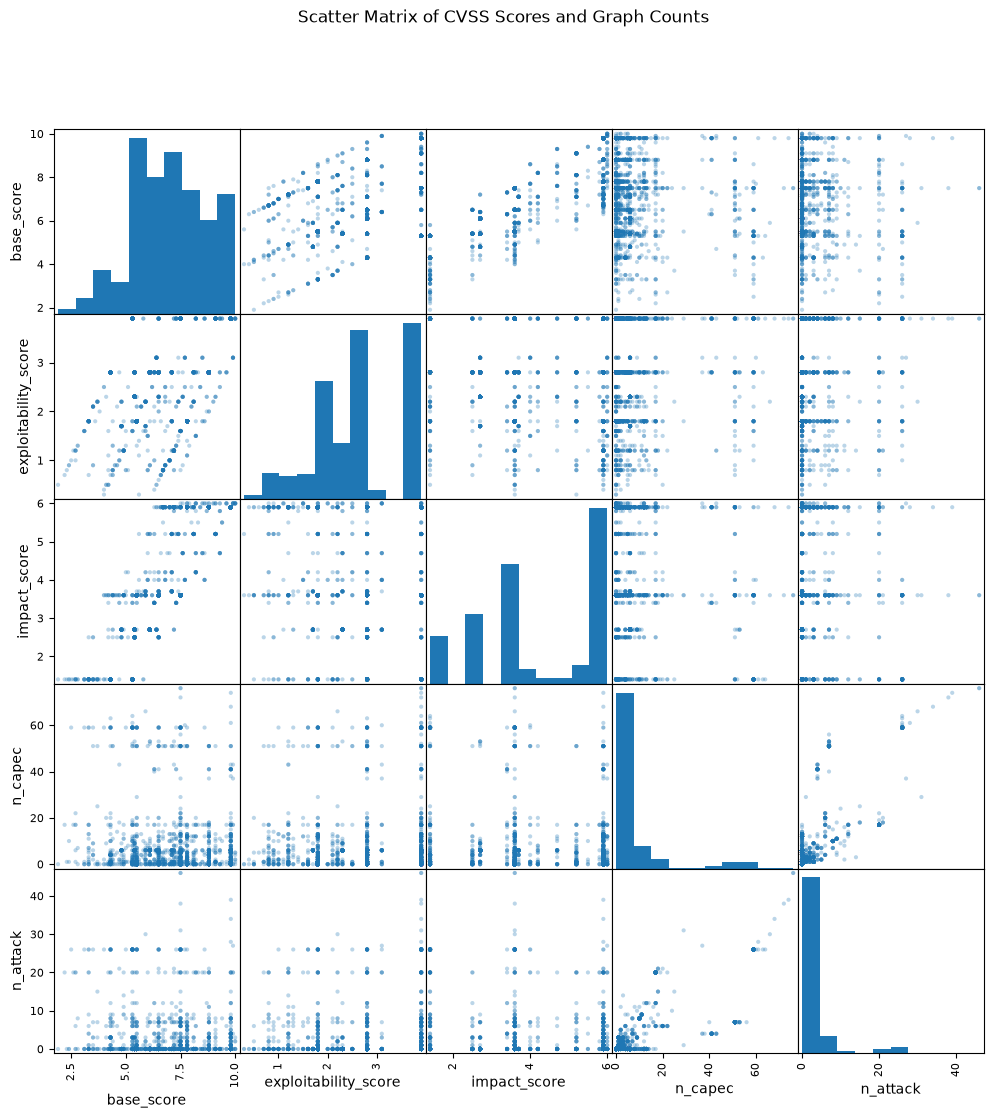

In [29]:
scatter_sample = df.sample(2000, random_state=42)  # Fixed random_state so the sample, and the plot, is the same every run

pd.plotting.scatter_matrix(
    scatter_sample[["base_score", "exploitability_score", "impact_score", "n_capec", "n_attack"]],
    figsize=(12, 12),
    alpha=0.3,
    diagonal="hist"
)
plt.suptitle("Scatter Matrix of CVSS Scores and Graph Counts")
plt.show()

Each panel plots one feature against another for the 2,000 sampled CVEs. base_score rises with impact_score (correlation 0.84) and with exploitability_score (0.45), which makes sense because the base score is built from those two parts. The diagonal lines in the base_score vs. exploitability_score panel each come from one impact value. n_capec and n_attack rise together (0.74), because ATT&CK links are found through CAPEC. The graph counts against the scores show no pattern, which matches the near-zero correlations in Task 4.

**Pair plot:** `sns.pairplot` makes the same kind of grid, but it can color the points by severity. We use the same 2,000-row sample and the three scores that make up CVSS.

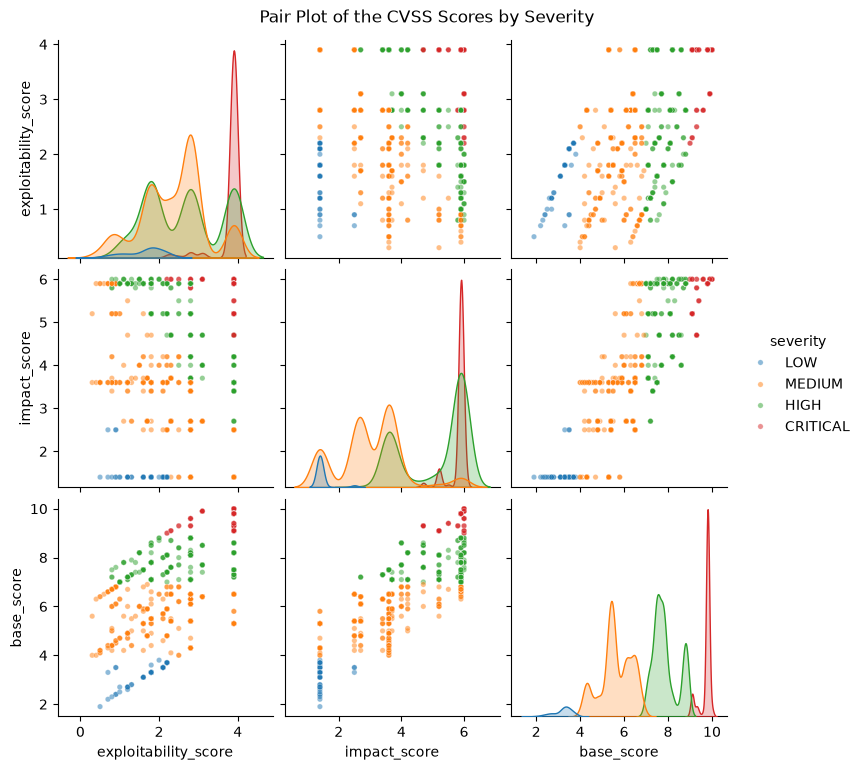

In [30]:
grid = sns.pairplot(
    scatter_sample,
    vars=["exploitability_score", "impact_score", "base_score"],
    hue="severity",
    hue_order=severity_order,
    plot_kws={"alpha": 0.5, "s": 15}
)
grid.figure.suptitle("Pair Plot of the CVSS Scores by Severity", y=1.02)
plt.show()

Coloring by severity shows that the severity levels are horizontal slices of base_score (bottom row). CRITICAL CVEs (red) sit at the top of both parts: exploitability near 3.9 and impact near 6.0. LOW CVEs (blue) mostly have the lowest impact score, 1.4. MEDIUM and HIGH overlap a lot on each part alone, so it takes both parts together to decide severity.

### Task 6

Task 6 looks for outliers and odd values by their cause: data entry, measurement, data processing, sampling, and natural. For each cause we find examples, then clean them in a copy of the data called `df_clean`, so `df` stays the same as in Tasks 1 to 5.

#### Checking the scores first

Before looking for outliers we check that the CVSS 3.x scores themselves are right. Every base score can be recalculated from its vector string (like `CVSS:3.1/AV:N/AC:L/...`) with the formula in the CVSS specification. We also check that each severity label matches its score band (LOW 0.1 to 3.9, MEDIUM 4.0 to 6.9, HIGH 7.0 to 8.9, CRITICAL 9.0 to 10.0).

In [31]:
import math

# CVSS 3.x metric weights from the official specification
WEIGHTS = {
    "AV": {"N": 0.85, "A": 0.62, "L": 0.55, "P": 0.2},
    "AC": {"L": 0.77, "H": 0.44},
    "UI": {"N": 0.85, "R": 0.62},
    "C": {"H": 0.56, "L": 0.22, "N": 0},
    "I": {"H": 0.56, "L": 0.22, "N": 0},
    "A": {"H": 0.56, "L": 0.22, "N": 0},
}

def roundup(x):
    """CVSS rounding: up to one decimal place."""
    i = round(x * 100000)
    return i / 100000.0 if i % 10000 == 0 else (math.floor(i / 10000) + 1) / 10.0

def cvss3_base_score(vector):
    m = dict(part.split(":") for part in vector.split("/")[1:])
    changed = m["S"] == "C"
    pr = {"N": 0.85, "L": 0.68 if changed else 0.62, "H": 0.5 if changed else 0.27}[m["PR"]]
    iss = 1 - (1 - WEIGHTS["C"][m["C"]]) * (1 - WEIGHTS["I"][m["I"]]) * (1 - WEIGHTS["A"][m["A"]])
    impact = 7.52 * (iss - 0.029) - 3.25 * (iss - 0.02) ** 15 if changed else 6.42 * iss
    exploitability = 8.22 * WEIGHTS["AV"][m["AV"]] * WEIGHTS["AC"][m["AC"]] * pr * WEIGHTS["UI"][m["UI"]]
    if impact <= 0:
        return 0.0
    return roundup(min(1.08 * (impact + exploitability), 10)) if changed else roundup(min(impact + exploitability, 10))

recalculated = df["vector_string"].map(cvss3_base_score)
score_mismatches = (recalculated - df["base_score"]).abs() > 0.05

bands = pd.cut(df["base_score"], bins=[0, 3.9, 6.9, 8.9, 10], labels=severity_order)
label_mismatches = bands.astype(str) != df["severity"]

print(f"Base scores checked: {len(df):,}")
print("Base scores that don't match their vector string:", score_mismatches.sum())
print("Severity labels that don't match their base score:", label_mismatches.sum())

Base scores checked: 307,239
Base scores that don't match their vector string: 0
Severity labels that don't match their base score: 0


All 307,239 base scores match the score recalculated from their vector string, and every severity label matches its score band. So the CVSS 3.x scores have no entry or calculation errors, and any outliers in them are real values.

#### Data entry errors

Some descriptions contain the replacement character `\ufffd` (shown as �). It appears when text is saved in one encoding and read in another, so a character was lost when the description was entered. We count them and show examples.

In [32]:
lost_char = df["description"].str.contains("\ufffd")
lost_apostrophe = df["description"].str.contains(r"[A-Za-z]\ufffd[st]\b")  # Like victim\ufffds or don\ufffdt

print("Descriptions with a lost character (\ufffd):", lost_char.sum())
print("Of those, a lost apostrophe:", lost_apostrophe.sum())

# Show the text around the lost character for a few examples
display(df.loc[lost_apostrophe, "description"].str.extract(r"(.{0,30}\ufffd.{0,15})")[0].head(4).to_frame("text around the lost character"))
display(df.loc[lost_char & ~lost_apostrophe, "description"].str.extract(r"(.{0,15}\ufffd.{0,15})")[0].head(4).to_frame("text around the lost character"))

Descriptions with a lost character (�): 63
Of those, a lost apostrophe: 45


,text around the lost character
154788,mation available in the victim�s browser leadi
174659,bility to logon to the product�s management co
191080,", or potentially impact a user�s local machine"
191329,to the override of the system�s configuration


,text around the lost character
154787,"edger, version � 100, does not"
180873,viding a patch �� ### Patches S
184357,ge Generation (�Cross-site Scri
184359,ct: EcoStruxure� Power Monitori


63 descriptions have a lost character. 45 of them are lost apostrophes, like "victim�s browser" (victim's). The other 18 lost a symbol, like the ® in "EcoStruxure�" or a quote mark, and there is no way to tell which symbol it was.

**Cleaning:** when � sits between a letter and an "s" or "t" at the end of a word, it was an apostrophe (victim's, don't). We put the apostrophe back in those spots only. The rest can't be recovered, so we leave them.

In [33]:
df_clean = df.copy()  # All cleaning is done on a copy, so df stays as Tasks 1 to 5 used it

# Put the apostrophe back only where a letter comes before and an s or t after
df_clean["description"] = df_clean["description"].str.replace(r"(?<=[A-Za-z])\ufffd(?=[st]\b)", "'", regex=True)

print("Lost characters before cleaning:", lost_char.sum())
print("Lost characters after cleaning:", df_clean["description"].str.contains("\ufffd").sum())

# The fix swaps one character for one character, so the same slice lines up before and after
examples = df.index[lost_apostrophe][:4]
positions = df.loc[examples, "description"].str.find("\ufffd")
display(pd.DataFrame({
    "cve_id": df.loc[examples, "cve_id"],
    "before": [df.at[i, "description"][max(p - 25, 0):p + 15] for i, p in positions.items()],
    "after": [df_clean.at[i, "description"][max(p - 25, 0):p + 15] for i, p in positions.items()],
}))

Lost characters before cleaning: 63
Lost characters after cleaning: 19


,cve_id,before,after
154788,CVE-2020-6324,n available in the victim�s browser lead,n available in the victim's browser lead
174659,CVE-2021-36741,y to logon to the product�s management c,y to logon to the product's management c
191080,CVE-2022-22727,potentially impact a user�s local machin,potentially impact a user's local machin
191329,CVE-2022-22811,he override of the system�s configuratio,he override of the system's configuratio


The apostrophes are back (victim's, product's, user's, system's). 19 descriptions still have a lost character, because we can't tell what symbol was there. We leave those as they are instead of guessing.

#### Measurement errors

CVSS v2 and v3 measure the same CVE with different formulas, so their scores don't line up. This is a measurement bias, not a mistake in the data. We compare the two scores for CVEs that have both.

In [34]:
has_both = df["cvss2_base_score"].notna()
gap = df.loc[has_both, "base_score"] - df.loc[has_both, "cvss2_base_score"]  # v3 minus v2 for the same CVE

print(f"CVEs with both a v2 and a v3 score: {has_both.sum():,}")
print(f"Average gap (v3 minus v2): {gap.mean():.2f}")
print(f"Share where v3 is higher: {(gap > 0).mean():.0%}")

v2_bias = gap.groupby(df.loc[has_both, "cvss2_severity"]).mean()
display(v2_bias.loc[["LOW", "MEDIUM", "HIGH"]].round(2).to_frame("average gap by v2 severity"))

CVEs with both a v2 and a v3 score: 124,244
Average gap (v3 minus v2): 1.51
Share where v3 is higher: 82%


,average gap by v2 severity
cvss2_severity,
LOW,2.31
MEDIUM,1.73
HIGH,0.64


124,244 CVEs have both a v2 and a v3 score. v3 is higher 82% of the time, by 1.51 points on average. The gap is biggest for CVEs that v2 calls LOW (2.31) and smallest for v2 HIGH (0.64), so v2 rates the less severe CVEs much lower than v3 does. Neither score is wrong. The two versions measure on different scales.

**Cleaning:** we add a new column, `cvss2_adjusted`, that shifts each v2 score by the average gap for its v2 severity level. The original `cvss2_base_score` is kept.

In [35]:
# Add the average gap for each v2 severity level, capped at the top of the scale
df_clean["cvss2_adjusted"] = (df_clean["cvss2_base_score"] + df_clean["cvss2_severity"].map(v2_bias)).clip(upper=10)

adjusted_gap = df_clean.loc[has_both, "base_score"] - df_clean.loc[has_both, "cvss2_adjusted"]
print(f"Average gap before adjusting: {gap.mean():.2f}")
print(f"Average gap after adjusting:  {adjusted_gap.mean():.2f}")

Average gap before adjusting: 1.51
Average gap after adjusting:  0.02


After the shift, the average gap drops from 1.51 to 0.02. cvss2_adjusted is now on about the same scale as base_score, so the two can be compared or combined.

#### Data processing errors

`n_cwe`, `n_capec`, and `n_attack` come from the knowledge graph export, not from NVD. If the export missed some links, those CVEs will have counts that are too low. We count each CVE's CWEs again from NVD's own `all_cwes` column and compare.

In [36]:
# Count each CVE's CWEs from NVD's own list (all_cwes) instead of the graph
nvd_cwe_links = (
    df[["cve_id", "all_cwes"]].dropna()
    .assign(cwe_id=lambda d: d["all_cwes"].str.split(";"))
    .explode("cwe_id")[["cve_id", "cwe_id"]]
)
n_cwe_nvd = df["cve_id"].map(nvd_cwe_links.groupby("cve_id").size()).fillna(0).astype(int)

print(f"CVEs where the graph's CWE count differs from NVD: {(df['n_cwe'] != n_cwe_nvd).sum():,}")
print(f"  graph has fewer CWEs than NVD: {(df['n_cwe'] < n_cwe_nvd).sum():,}")
print(f"  graph has more CWEs than NVD:  {(df['n_cwe'] > n_cwe_nvd).sum():,}")
print(f"  graph has 0 but NVD lists one: {((df['n_cwe'] == 0) & (n_cwe_nvd > 0)).sum():,}")

# Why: is the CWE missing from the graph entirely, or is the CVE newer than the graph export?
missing = nvd_cwe_links.merge(cve_cwe, on=["cve_id", "cwe_id"], how="left", indicator=True).query('_merge == "left_only"')
missing_years = df.loc[df["cve_id"].isin(missing["cve_id"]), "published"].dt.year
print(f"Missing links to a CWE the graph doesn't have: {(~missing['cwe_id'].isin(cwes['cwe_id'])).mean():.0%}")
print(f"CVEs with missing links published in 2026: {(missing_years == 2026).mean():.0%}")

display(df.loc[(df["n_cwe"] == 0) & (n_cwe_nvd > 0), ["cve_id", "all_cwes", "n_cwe"]].head(4))

CVEs where the graph's CWE count differs from NVD: 8,100
  graph has fewer CWEs than NVD: 8,100
  graph has more CWEs than NVD:  0
  graph has 0 but NVD lists one: 7,102
Missing links to a CWE the graph doesn't have: 42%
CVEs with missing links published in 2026: 59%


,cve_id,all_cwes,n_cwe
6720,CVE-2000-1254,CWE-310,0
8317,CVE-2003-1605,CWE-255,0
11026,CVE-2004-2778,CWE-264,0
11027,CVE-2004-2779,CWE-399,0


8,100 CVEs have fewer CWEs in the graph than NVD lists, and none have more. 7,102 of them have 0 CWEs in the graph even though NVD lists one, like CVE-2000-1254 with CWE-310. There are two reasons. 42% of the missing links point to old CWE categories that are not in the graph at all, and 59% of the affected CVEs are from 2026, newer than the graph export. So many of the 0s that showed up as outliers in Task 2 are not real. They come from the export.

**Cleaning:** we rebuild the counts the same way the Setup cell does (CVE to CWE to CAPEC to ATT&CK), but start from NVD's CWE list.

In [37]:
# Redo the Setup cell's CVE -> CWE -> CAPEC -> ATT&CK steps, starting from NVD's CWE list
nvd_cve_capec = nvd_cwe_links.merge(capec_cwe, on="cwe_id")[["cve_id", "capec_id"]].drop_duplicates()
nvd_cve_attack = nvd_cve_capec.merge(capec_attack, on="capec_id")[["cve_id", "attack_id"]].drop_duplicates()

df_clean["n_cwe"] = n_cwe_nvd
df_clean["n_capec"] = df["cve_id"].map(nvd_cve_capec.groupby("cve_id").size()).fillna(0).astype(int)
df_clean["n_attack"] = df["cve_id"].map(nvd_cve_attack.groupby("cve_id").size()).fillna(0).astype(int)

graph_counts = ["n_cwe", "n_capec", "n_attack"]
display(pd.DataFrame({
    "CVEs with 0 before": [(df[c] == 0).sum() for c in graph_counts],
    "CVEs with 0 after": [(df_clean[c] == 0).sum() for c in graph_counts],
    "CVEs that changed": [(df[c] != df_clean[c]).sum() for c in graph_counts],
}, index=graph_counts))

,CVEs with 0 before,CVEs with 0 after,CVEs that changed
n_cwe,33473,26371,8100
n_capec,84601,81352,3252
n_attack,216807,215529,1279


With the counts rebuilt, 7,102 fewer CVEs have 0 CWEs, 3,249 fewer have 0 CAPEC patterns, and 1,278 fewer have 0 ATT&CK techniques. n_cpe also comes from the graph, but it can't be rebuilt the same way, because our NVD file only lists vendors and products, not the full CPE list.

#### Sampling errors

`cvss3_source` tells us who scored each CVE: NVD itself (Primary) or the organization that reported it (Secondary). If the mix changes over time, the data is not one consistent sample. We plot the share of Secondary scores by year and compare the severity mix of the two groups.

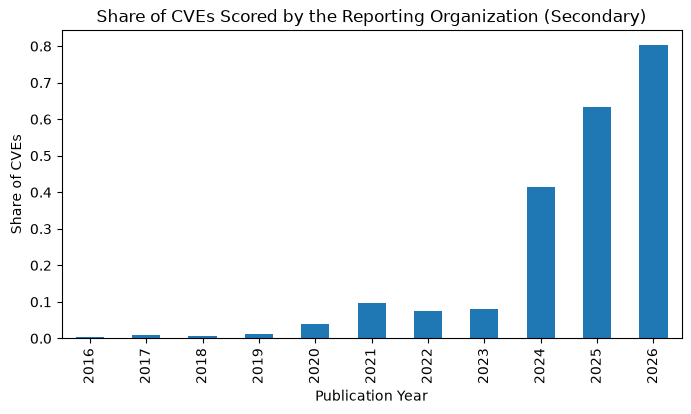

severity,LOW,MEDIUM,HIGH,CRITICAL
cvss3_source,,,,
Primary,0.017,0.431,0.395,0.157
Secondary,0.033,0.426,0.430,0.111


In [38]:
pub_year = df["published"].dt.year
secondary_share = (df["cvss3_source"] == "Secondary").groupby(pub_year).mean().loc[2016:]

plt.figure(figsize=(8, 4))
secondary_share.plot(kind="bar")
plt.title("Share of CVEs Scored by the Reporting Organization (Secondary)")
plt.xlabel("Publication Year")
plt.ylabel("Share of CVEs")
plt.show()

display(df.groupby("cvss3_source")["severity"].value_counts(normalize=True).unstack()[severity_order].round(3))

Up to 2023, at least 90% of v3 scores each year came from NVD. From 2024 on, most come from the reporting organizations: 42% in 2024, 63% in 2025, and 80% in 2026. The two groups score differently. Secondary scores are CRITICAL less often (11.1% vs. 15.7%) and LOW more often (3.3% vs. 1.7%). So recent years were scored by a different group, which could look like severity dropping over time when only the scorer changed.

NVD only started giving v3 scores in 2016, so the CVEs published earlier are the few that were scored later, not a full sample of their years. We compare them with the rest.

In [39]:
legacy = pub_year < 2016

display(pd.DataFrame({
    "CVEs": [legacy.sum(), (~legacy).sum()],
    "mean base score": [df.loc[legacy, "base_score"].mean(), df.loc[~legacy, "base_score"].mean()],
    "share CRITICAL": [(df.loc[legacy, "severity"] == "CRITICAL").mean(), (df.loc[~legacy, "severity"] == "CRITICAL").mean()],
}, index=["published before 2016", "published 2016 or later"]).round(3))

,CVEs,mean base score,share CRITICAL
published before 2016,1331,7.675,0.208
published 2016 or later,305908,7.069,0.140


Only 1,331 CVEs come from before 2016. Their average base score is 7.7, and 20.8% are CRITICAL, compared with 7.1 and 14.0% for the rest. These older CVEs were likely scored later because they still mattered, so they are more severe than a typical CVE from those years.

**Cleaning:** these CVEs are real, so we don't remove them. We add an `is_legacy` flag and keep `cvss3_source`, so a model can split or stratify on them.

In [40]:
df_clean["is_legacy"] = df_clean["published"].dt.year < 2016

display(df_clean.groupby(["is_legacy", "cvss3_source"]).size().unstack().rename_axis(index="is_legacy", columns="scored by"))

scored by,Primary,Secondary
is_legacy,,
False,194043,111865
True,953,378


Most legacy CVEs (953 of 1,331) were scored by NVD. With these two columns, a model can be trained and tested on the same mix of sources and eras, so the mix doesn't throw it off.

#### Natural outliers

Some CVEs really do affect thousands of products or link to many attack patterns. We show the largest values of `n_cpe` and `n_capec`.

In [41]:
pd.set_option("display.max_colwidth", 70)
display(df.nlargest(3, "n_cpe")[["cve_id", "n_cpe", "vendors", "description"]])
display(df.nlargest(3, "n_capec")[["cve_id", "n_capec", "n_attack", "all_cwes"]])

,cve_id,n_cpe,vendors,description
187752,CVE-2021-3942,2723,hp,Certain HP Print products and Digital Sending products may be vuln...
214296,CVE-2022-4894,1023,hp;samsung,Certain HP and Samsung Printer software packages may potentially b...
226532,CVE-2023-1329,957,hp,A potential security vulnerability has been identified for certain...


,cve_id,n_capec,n_attack,all_cwes
370123,CVE-2026-62519,134,54,CWE-20;CWE-200;CWE-284;CWE-732
359920,CVE-2026-46910,132,51,CWE-20;CWE-200;CWE-284;CWE-306;CWE-400
369564,CVE-2026-60620,127,51,CWE-20;CWE-200;CWE-284;CWE-400


The CVE with the most affected products is CVE-2021-3942, with 2,723. It covers many HP printer models, and each model and firmware version is listed as its own product. The next two are also printer bugs (HP and Samsung). The highest CAPEC count is 134, for CVE-2026-62519. It links to broad CWEs like CWE-20 (improper input validation) and CWE-284 (improper access control), which map to many attack patterns. These values are extreme but real.

To see how much these outliers matter, we compare the average `n_cpe` for each severity level with and without the top 1% of CVEs.

In [42]:
cutoff = df["n_cpe"].quantile(0.99)

display(pd.DataFrame({
    "with outliers": df.groupby("severity")["n_cpe"].mean(),
    f"without the top 1% (n_cpe > {cutoff:.0f})": df[df["n_cpe"] <= cutoff].groupby("severity")["n_cpe"].mean(),
}).loc[severity_order].round(2))

,with outliers,without the top 1% (n_cpe > 26)
severity,,
LOW,1.37,0.95
MEDIUM,1.77,1.04
HIGH,2.63,1.18
CRITICAL,2.37,1.23


With the outliers, HIGH CVEs seem to affect the most products (2.63). Without the top 1% (n_cpe over 26), the order changes: CRITICAL comes first (1.23), and the averages rise steadily from LOW to CRITICAL. So a few huge CVEs are enough to change the conclusion, and n_cpe needs to be handled before modeling.

**Cleaning:** these values are real, so we keep them. Instead we add log versions of the long-tailed counts. `np.log1p` takes log(1 + x), which pulls in the long tail and still works for counts of 0.

,skew before,skew after log
n_cpe,35.28,3.58
n_capec,2.76,0.50
n_attack,3.27,1.56


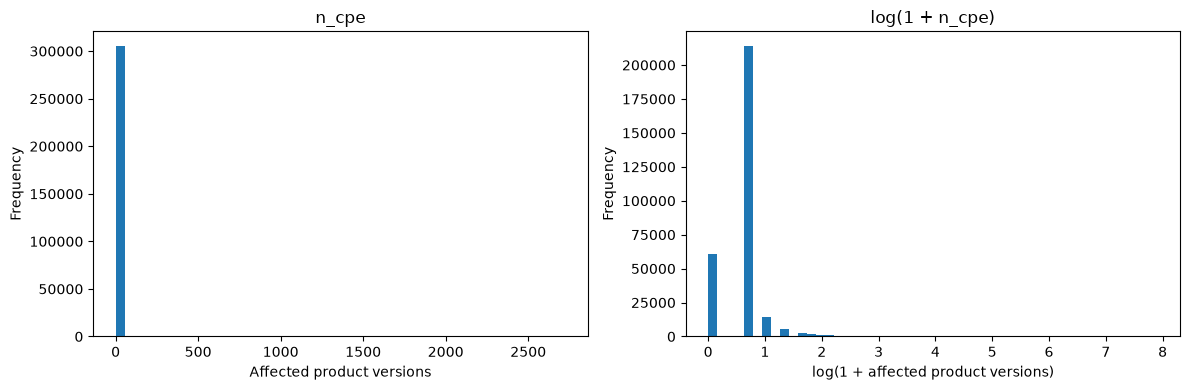

In [43]:
log_cols = ["n_cpe", "n_capec", "n_attack"]
for col in log_cols:
    df_clean[f"log_{col}"] = np.log1p(df_clean[col])  # log(1 + x), so a count of 0 stays 0

display(pd.DataFrame({
    "skew before": [df_clean[c].skew() for c in log_cols],
    "skew after log": [df_clean[f"log_{c}"].skew() for c in log_cols],
}, index=log_cols).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_clean["n_cpe"].plot(kind="hist", bins=50, ax=axes[0], title="n_cpe")
df_clean["log_n_cpe"].plot(kind="hist", bins=50, ax=axes[1], title="log(1 + n_cpe)")
axes[0].set_xlabel("Affected product versions")
axes[1].set_xlabel("log(1 + affected product versions)")
plt.tight_layout()
plt.show()

The log makes all three counts much less skewed. n_cpe goes from 35.28 to 3.58, n_capec from 2.76 to 0.50, and n_attack from 3.27 to 1.56. In the right histogram, the 0s, 1s, and the tail are visible instead of all sitting in one bar, and no CVEs were removed.

#### Summary

A table of every cause, what we found, and how we cleaned it, plus the shape of `df_clean` next to `df`.

In [44]:
summary = pd.DataFrame([
    ["Data entry", f"{lost_char.sum()} descriptions with a lost character", f"Restored the apostrophe in {lost_apostrophe.sum()} descriptions"],
    ["Measurement", f"v3 scores average {gap.mean():.2f} points higher than v2", "Added cvss2_adjusted with the bias removed"],
    ["Data processing", f"{(df['n_cwe'] != n_cwe_nvd).sum():,} CVEs missing CWE links in the graph", "Recounted n_cwe, n_capec, and n_attack from NVD's CWE list"],
    ["Sampling", "Secondary-scored and pre-2016 CVEs differ from the rest", "Added is_legacy and kept cvss3_source to split or stratify on"],
    ["Natural", f"n_cpe reaches {df['n_cpe'].max():,}", "Kept them and added log versions of n_cpe, n_capec, and n_attack"],
], columns=["Cause", "Found", "Cleaning"])

display(summary)
print("df shape:      ", df.shape)
print("df_clean shape:", df_clean.shape)

,Cause,Found,Cleaning
0,Data entry,63 descriptions with a lost character,Restored the apostrophe in 45 descriptions
1,Measurement,v3 scores average 1.51 points higher than v2,Added cvss2_adjusted with the bias removed
2,Data processing,"8,100 CVEs missing CWE links in the graph","Recounted n_cwe, n_capec, and n_attack from NVD's CWE list"
3,Sampling,Secondary-scored and pre-2016 CVEs differ from the rest,Added is_legacy and kept cvss3_source to split or stratify on
4,Natural,"n_cpe reaches 2,723","Kept them and added log versions of n_cpe, n_capec, and n_attack"


df shape:       (307239, 32)
df_clean shape: (307239, 37)


df_clean has the same 307,239 rows as df. No CVEs were removed, because every outlier we found was either fixable or real. It has 5 new columns: cvss2_adjusted, is_legacy, and log versions of n_cpe, n_capec, and n_attack. The descriptions and graph counts were fixed in place.